# Part 9: Levelling the playing field: propensity scores without the mystery

*Series: Who Will Stay Because of Us? Uplift Modelling and Causal Inference for Client Attrition*

Part 8 showed that when RMs choose, the clients who got pricing were easier to keep to begin with, and the naive comparison doubled the effect of pricing. This notebook levels the playing field.

**In this notebook**

1. A two-segment example worked by hand: how a 27-point illusion becomes an honest 13.
2. Doing it on the bank's data by simple **counting** (stratification).
3. The **propensity model**: the same idea for many characteristics at once.
4. **Weights**, overlap and trimming, and checking that the groups now look alike.
5. The corrected estimate against the truth.
6. Training the uplift model with weights, and why validating it is still hard.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uplift_series import SERIES_SEED, analysis_pool, generate_bank, naive_uplift, true_average_uplift
from uplift_series import plotting as P
from uplift_series.evaluation import assign_bins, uplift_by_bin
from uplift_series.modeling import TLearner, split_pool
from uplift_series.propensity import (PropensityModel, default_strata, ipw_weights,
                                      standardized_mean_differences, stratified_effect, weighted_effect)

P.set_style()
pd.set_option("display.float_format", "{:.3f}".format)

pool = analysis_pool(generate_bank(assignment="rm_biased", seed=SERIES_SEED))
truth = true_average_uplift(pool)
print(f"Naive estimate {100 * naive_uplift(pool):.1f} pts   True effect {100 * truth:.1f} pts")

Naive estimate 14.7 pts   True effect 7.7 pts


## 1. A worked example by hand

Imagine only two kinds of client:

- **Segment X:** large, long-standing, easy. Pricing cuts their churn by 5 points.
- **Segment Y:** smaller, newer, harder. Pricing cuts their churn by 15 points.

RMs mostly picked X clients.

In [2]:
seg = pd.DataFrame({
    "treated": [700, 300], "control": [300, 3700],
    "treated churn": [0.10, 0.30], "control churn": [0.15, 0.45],
}, index=["X: easy", "Y: hard"])
seg["true effect (pts)"] = 100 * (seg["control churn"] - seg["treated churn"])

treated_churn = (seg["treated"] * seg["treated churn"]).sum() / seg["treated"].sum()
control_churn = (seg["control"] * seg["control churn"]).sum() / seg["control"].sum()
print(f"Naive: control {control_churn:.2%} - treated {treated_churn:.2%} = {100 * (control_churn - treated_churn):.2f} pts")
seg

Naive: control 42.75% - treated 16.00% = 26.75 pts


,treated,control,treated churn,control churn,true effect (pts)
X: easy,700,300,0.100,0.150,5.000
Y: hard,300,3700,0.300,0.450,15.000


Pricing never achieves more than 15 points anywhere, yet the naive comparison says 26.75. The treated group is 70% easy clients; the control group is 92% hard clients. The comparison is really *easy clients versus hard clients*.

**The propensity score** is the probability that a client like this one was picked for pricing. Here it is pure counting: 700 of 1,000 X clients were picked (0.70), and 300 of 4,000 Y clients (0.075).

**Weighting** makes each client "speak for" a number of similar clients, like a pollster up-weighting under-sampled respondents:

- treated client: weight = 1 / propensity,
- control client: weight = 1 / (1 − propensity).

In [3]:
seg["clients"] = seg["treated"] + seg["control"]
seg["propensity"] = seg["treated"] / seg["clients"]
seg["treated weight"] = 1 / seg["propensity"]
seg["control weight"] = 1 / (1 - seg["propensity"])
seg["weighted treated"] = seg["treated"] * seg["treated weight"]
seg["weighted control"] = seg["control"] * seg["control weight"]

w_treated = (seg["weighted treated"] * seg["treated churn"]).sum() / seg["weighted treated"].sum()
w_control = (seg["weighted control"] * seg["control churn"]).sum() / seg["weighted control"].sum()
within = (seg["clients"] * seg["true effect (pts)"]).sum() / seg["clients"].sum()
print(f"Weighted: control {w_control:.0%} - treated {w_treated:.0%} = {100 * (w_control - w_treated):.0f} pts")
print(f"Within-segment comparison, averaged by segment size: {within:.0f} pts")
seg[["propensity", "treated weight", "control weight", "weighted treated", "weighted control"]]

Weighted: control 39% - treated 26% = 13 pts
Within-segment comparison, averaged by segment size: 13 pts


,propensity,treated weight,control weight,weighted treated,weighted control
X: easy,0.700,1.429,3.333,1000.000,1000.000
Y: hard,0.075,13.333,1.081,4000.000,4000.000


After weighting, both groups contain the equivalent of 1,000 easy and 4,000 hard clients, the same mix as the whole population, so the remaining difference belongs to pricing: **13 points**, the true average.

Two views of one idea:

- **Stratification:** compare treated and control clients only *inside* each segment, then average by segment size.
- **Inverse probability weighting (IPW):** reweight so the two groups have the same mix, then compare once.

## 2. Counting on the bank's data: stratification

Real clients differ in many ways at once. A practical counting recipe:

1. pick a few drivers of both the RM's choice and churn;
2. cut each into a few bands;
3. compare treated and control churn inside every cell;
4. drop cells without both treated and control clients (no **common support**);
5. average the cell results by cell size.

`default_strata` uses tenure, RM meetings and revenue (three bands each), complaints (yes/no) and corporate event (yes/no).

In [4]:
strat = stratified_effect(pool, default_strata(pool))
print(f"Stratified estimate: {100 * strat['estimate']:.1f} pts  (naive {100 * naive_uplift(pool):.1f}, truth {100 * truth:.1f})")
print(f"Cells used: {strat['cells_used']} of {strat['cells_total']}; clients dropped for no overlap: {strat['clients_dropped']}")
strat["cells"].head(8)

Stratified estimate: 8.1 pts  (naive 14.7, truth 7.7)
Cells used: 88 of 108; clients dropped for no overlap: 206


,clients,treated,control,propensity,effect
cell,,,,,
short | 0-1 | small | no complaint | no event,190,13,177,0.068,0.217
short | 0-1 | large | no complaint | no event,173,36,137,0.208,0.101
short | 0-1 | medium | no complaint | no event,168,18,150,0.107,0.116
short | 0-1 | medium | complained | no event,168,12,156,0.071,0.115
mid | 0-1 | large | no complaint | no event,150,42,108,0.280,0.087
mid | 0-1 | small | complained | no event,149,20,129,0.134,0.144
short | 0-1 | large | complained | no event,146,18,128,0.123,0.076
long | 0-1 | small | no complaint | no event,145,48,97,0.331,0.092


Counting alone removes most of the illusion. It also makes the RMs' behaviour visible: the propensity column shows how much more often some kinds of client were picked.

Counting stops scaling with more drivers: five drivers with four bands each make 1,024 cells, most of them empty. That is where a model takes over.

## 3. The propensity model

A **logistic regression** predicts the probability of being picked for pricing from all the features at once. It is the counting idea, smoothed across many characteristics.

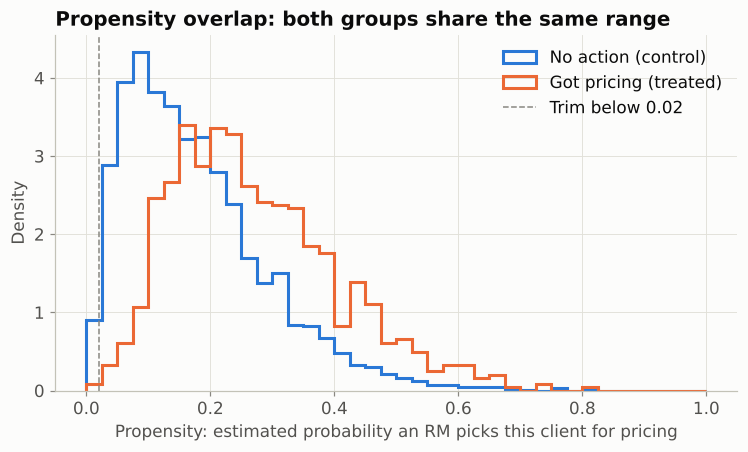

Propensity range: 0.008 to 0.819; clients trimmed at 0.02 / 0.98: 50


In [5]:
prop = PropensityModel().fit(pool)
pool["propensity"] = prop.predict(pool)

fig, ax = plt.subplots(figsize=(8, 4.2))
bins = np.linspace(0, 1, 41)
ax.hist(pool.loc[pool["treated"] == 0, "propensity"], bins=bins, density=True, histtype="step",
        linewidth=2, color=P.BLUE, label="No action (control)")
ax.hist(pool.loc[pool["treated"] == 1, "propensity"], bins=bins, density=True, histtype="step",
        linewidth=2, color=P.ORANGE, label="Got pricing (treated)")
ax.axvline(0.02, color=P.INK_MUTED, linestyle="--", linewidth=1, label="Trim below 0.02")
ax.set_xlabel("Propensity: estimated probability an RM picks this client for pricing")
ax.set_ylabel("Density")
ax.legend(loc="upper right")
ax.set_title("Propensity overlap: both groups share the same range")
P.save(fig, "09_overlap")
plt.show()
print(f"Propensity range: {pool['propensity'].min():.3f} to {pool['propensity'].max():.3f}; "
      f"clients trimmed at 0.02 / 0.98: {((pool['propensity'] < 0.02) | (pool['propensity'] > 0.98)).sum()}")

Treated clients sit further right, as expected: they were likelier to be picked. What matters is **overlap**: across the range, both groups are present, so every treated client has comparable controls and vice versa.

A client with a propensity near zero who *was* treated would get an enormous weight and could swing the result alone. The weights are therefore **trimmed**: propensities are clipped to the range 0.02 to 0.98, capping any weight at 50.

## 4. Weights and balance

Now apply the weights and repeat Part 8's balance check.

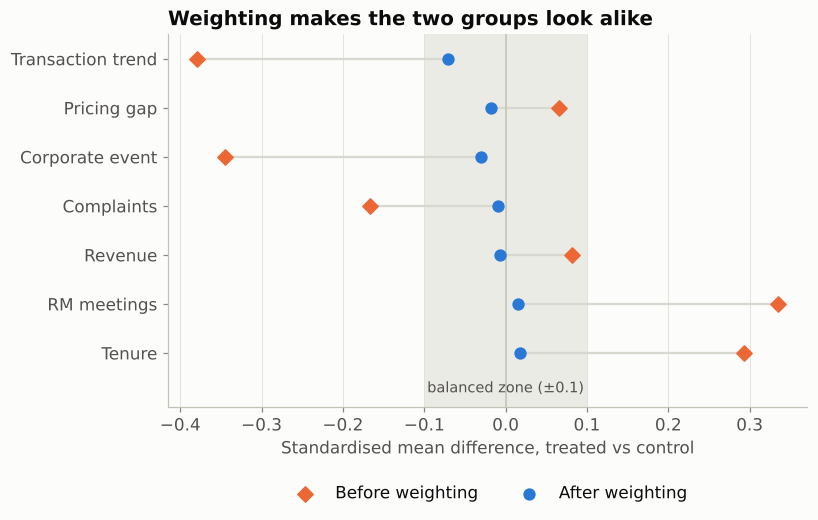

In [6]:
pool["ipw"] = ipw_weights(pool["treated"], pool["propensity"])
cols = ["tenure_years", "rm_meetings_6m", "revenue_ttm", "complaints_6m", "corporate_event",
        "pricing_gap", "txn_volume_trend"]
labels = {"tenure_years": "Tenure", "rm_meetings_6m": "RM meetings", "revenue_ttm": "Revenue",
          "complaints_6m": "Complaints", "corporate_event": "Corporate event",
          "pricing_gap": "Pricing gap", "txn_volume_trend": "Transaction trend"}
balance = pd.DataFrame({
    "Before weighting": standardized_mean_differences(pool, cols),
    "After weighting": standardized_mean_differences(pool, cols, weight="ipw"),
})
balance.index = [labels[c] for c in balance.index]

fig, ax = plt.subplots(figsize=(7.5, 4.4))
y = np.arange(len(balance))
ax.axvspan(-0.1, 0.1, color=P.GRID, alpha=0.6, linewidth=0)
ax.axvline(0, color=P.BASELINE, linewidth=1)
for i in y:
    ax.plot(balance.iloc[i], [i, i], color=P.BACKGROUND_POINTS, linewidth=1.5, zorder=1)
ax.scatter(balance["Before weighting"], y, color=P.ORANGE, marker="D", s=50, label="Before weighting", zorder=3)
ax.scatter(balance["After weighting"], y, color=P.BLUE, s=50, label="After weighting", zorder=3)
ax.set_yticks(y, balance.index)
ax.set_ylim(-1.1, len(balance) - 0.5)
ax.text(0, -0.8, "balanced zone (±0.1)", ha="center", color=P.INK_SECONDARY, fontsize=9.5)
ax.set_xlabel("Standardised mean difference, treated vs control")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
ax.grid(axis="y", visible=False)
ax.set_title("Weighting makes the two groups look alike")
P.save(fig, "09_balance")
plt.show()

Every characteristic moves into, or close to, the balanced zone. After weighting, the treated and control groups look like the same population, which is what a randomised experiment would have given us.

## 5. The corrected estimate

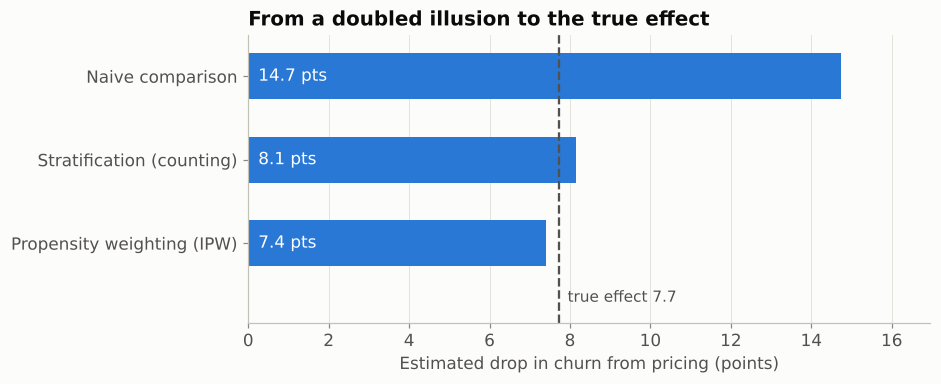

,points,truth
Naive comparison,14.700,7.700
Stratification (counting),8.100,7.700
Propensity weighting (IPW),7.400,7.700


In [7]:
estimates = pd.Series({
    "Naive comparison": naive_uplift(pool),
    "Stratification (counting)": strat["estimate"],
    "Propensity weighting (IPW)": weighted_effect(pool, "ipw"),
}) * 100

fig, ax = plt.subplots(figsize=(8, 3.4))
names = list(estimates.index)[::-1]
bars = ax.barh(names, estimates[names], color=P.BLUE, height=0.55)
ax.axvline(100 * truth, color=P.INK_SECONDARY, linestyle="--", linewidth=1.5)
ax.set_ylim(-0.95, 2.5)
ax.text(100 * truth + 0.2, -0.7, f"true effect {100 * truth:.1f}", color=P.INK_SECONDARY, fontsize=10)
for b, v in zip(bars, estimates[names]):
    ax.text(0.25, b.get_y() + b.get_height() / 2, f"{v:.1f} pts", ha="left", va="center", color="white", fontsize=11)
ax.set_xlim(0, estimates.max() * 1.15)
ax.set_xlabel("Estimated drop in churn from pricing (points)")
ax.grid(axis="y", visible=False)
ax.set_title("From a doubled illusion to the true effect")
P.save(fig, "09_estimates")
plt.show()
estimates.round(1).to_frame("points").assign(truth=round(100 * truth, 1))

Both corrections land close to the true effect, starting from an estimate almost twice as large.

## 6. Training the uplift model with weights

The same weights can be passed to XGBoost, so each of the T-learner's two models learns from a balanced picture. Compare three T-learners on the same test clients: trained on RM-chosen history without weights, with weights, and (for reference) on randomised history.

In [8]:
train, test = split_pool(pool, test_size=0.3, seed=0)
prop_train = PropensityModel().fit(train)
for d in (train, test):
    d["propensity"] = prop_train.predict(d)
    d["ipw"] = ipw_weights(d["treated"], d["propensity"])

random_train, _ = split_pool(analysis_pool(generate_bank(assignment="random", seed=SERIES_SEED)), 0.3, seed=0)
test["unweighted"] = TLearner().fit(train).predict_uplift(test)
test["weighted"] = TLearner().fit(train, sample_weight="ipw").predict_uplift(test)
test["random_history"] = TLearner().fit(random_train).predict_uplift(test)

K = 300
best = test.nlargest(K, "true_uplift")["true_uplift"].sum()
pd.DataFrame({
    name: {
        "average predicted uplift (pts)": 100 * test[col].mean(),
        "correlation with true uplift": np.corrcoef(test[col], test["true_uplift"])[0, 1],
        "share of best possible (300 calls)": test.nlargest(K, col)["true_uplift"].sum() / best,
    }
    for name, col in {"RM history, no weights": "unweighted",
                      "RM history, IPW weights": "weighted",
                      "Randomised history (reference)": "random_history"}.items()
}).assign(**{"truth": [100 * test["true_uplift"].mean(), np.nan, np.nan]})

,"RM history, no weights","RM history, IPW weights",Randomised history (reference),truth
average predicted uplift (pts),14.559,9.361,9.238,8.111
correlation with true uplift,0.230,0.537,0.530,NaN
share of best possible (300 calls),0.437,0.751,0.701,NaN


Weighting repairs most of the damage: the average predicted uplift comes back down towards the truth, and the ranking becomes about as good as one trained on randomised data.

### The catch: checking it is still hard

Part 5's validation can be weighted too. But weights amplify noise: a few treated clients with large weights dominate each bin.

In [9]:
check = uplift_by_bin(test, "weighted", 5, weight="ipw")
check["true_uplift"] = test.groupby(assign_bins(test, "weighted", 5))["true_uplift"].mean()
treated_w = test.loc[test["treated"] == 1, "ipw"]
print(f"Treated test clients: {len(treated_w)}; effective sample size after weighting: "
      f"{treated_w.sum() ** 2 / (treated_w ** 2).sum():.0f}")
(100 * check[["predicted_uplift", "actual_uplift", "true_uplift"]]).round(1).rename_axis("bin")

Treated test clients: 293; effective sample size after weighting: 154


,predicted_uplift,actual_uplift,true_uplift
bin,,,
1,26.100,2.100,16.700
2,16.200,-1.000,12.300
3,11.100,12.000,8.600
4,5.400,8.100,3.600
5,-12.000,-3.100,-0.600


The true uplift (which a bank never sees) falls neatly from the first bin to the last, so the weighted model ranks well. But the weighted "actual" column bounces around and would not convince anyone: weighting has cut about 290 treated test clients to the information content of about 150, roughly 30 per bin.

That is the honest limit of working with history: propensity weighting can **correct** an estimate, but proving the correction worked needs data that was not chosen by people.

## Takeaways

- The **propensity score** is the probability a client like this one was picked. With a few segments it is just counting.
- **Stratification** compares within cells of look-alikes; **IPW** reweights so both groups share the same mix. Here both took a 14.7-point illusion back to the 7.7-point truth.
- Check **overlap**, **trim** extreme propensities, and confirm **balance** with standardised mean differences.
- Passing the weights to the T-learner repairs most of the ranking damage from RM selection.
- Weighted validation on a small test set is **noisy**. Propensity methods also only fix what is **measured**.

**Next, Part 10:** what weighting cannot fix (hidden reasons for the RM's choice), the random holdout that solves it, and the whole pipeline in one place.